# Simulación de Monte Carlo y valoración de una call asiática

Se generan trayectorias de CAT, MRK y MSFT mediante un movimiento browniano geométrico correlacionado y se calcula el payoff de una call asiática a partir de la suma de sus medias geométricas temporales. Las trayectorias comparten un tramo inicial y después evolucionan de forma independiente.

- **Cartera:** CAT, MRK y MSFT, en ese orden en todas las matrices.
- **Simulación:** 100.000 trayectorias, 20 pasos trimestrales y cinco años.
- **Tramo común:** los cinco primeros pasos tienen los mismos precios en todas las simulaciones de cada activo; los 15 pasos restantes son continuaciones independientes.
- **Contrato:** precios iniciales normalizados $S_0=[1,1,1]$, tipo libre de riesgo del 1 %, sin dividendos y strike 3.
- **Supuestos:** volatilidades y correlaciones constantes durante la simulación.
- **Reproducibilidad:** semilla 42; se muestran el abanico completo y las primeras cinco trayectorias.

La valoración se condiciona al tramo inicial compartido. **Entradas:** parámetros históricos incorporados en el notebook. **Dependencias:** NumPy, pandas, Matplotlib e IPython. La ejecución se realiza de arriba abajo y no requiere archivos de datos externos ni conexión a internet.

La configuración gráfica BBVA está incluida en el notebook. Los ocho gráficos se guardan automáticamente como PNG en `Graficos/`, dentro de la carpeta de ejecución. Se incluyen la tabla trimestral completa, la validación de precios descontados, una referencia de fórmula cerrada aproximada para la cesta y un estudio de convergencia. El contraste exacto de CAT se conserva como comprobación auxiliar. Las referencias condicionada e incondicional se presentan separadamente.


In [1]:
from time import perf_counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from packages.bbva_graficos import configurar_graficos, guardar_mpl, anotar_fuente, cerrar_grafico, fmt_es, BBVA, PALETA
configurar_graficos()

pd.options.display.float_format = lambda valor: fmt_es(valor, 6)

## 1. Cartera y parámetros históricos

Las volatilidades anuales y las correlaciones proceden de la selección de cartera realizada sobre `Datos/Transformados/dowjones_diario_2016_2025.csv`. Se emplean los rendimientos logarítmicos diarios del **05/01/2016 al 31/12/2025**. La volatilidad se anualizó con **252 sesiones bursátiles** y la correlación se calculó con el coeficiente de Pearson.

Se incorporan los valores de `outputs/parametros_montecarlo.json` con la precisión de seis decimales utilizada por el equipo. Estos archivos documentan la procedencia de los parámetros y no son necesarios para ejecutar el notebook.

El histórico se utiliza para estimar las volatilidades y las correlaciones. El crecimiento esperado de las trayectorias se fija en la tasa libre de riesgo, de acuerdo con el marco de valoración neutral al riesgo.


In [2]:
activos = ["CAT", "MRK", "MSFT"]

# Parámetros calculados por el equipo sobre los rendimientos logarítmicos.
sigma = np.array([0.304449, 0.226614, 0.267572])
rho = np.array([
    [1.0, 0.249833, 0.394764],
    [0.249833, 1.0, 0.276564],
    [0.394764, 0.276564, 1.0],
])


## 2. Configuración de la simulación

El horizonte de cinco años se divide en **20 pasos de 0,25 años**. Los instantes simulados son $t_j=j\Delta t$, con $j=1,\ldots,20$: desde $t=0,25$ hasta $t=5$.

Se genera una sola trayectoria inicial de cinco pasos y se comparte entre las 100.000 simulaciones. Este tramo alcanza **1,25 años**. A partir del sexto paso, cada simulación continúa con nuevos incrementos aleatorios independientes de las demás, manteniendo la correlación entre los tres activos.

El precio inicial $S_0$ corresponde a $t=0$ y se incluye en la representación de las trayectorias. Las medias geométricas del payoff utilizan las **20 observaciones futuras**, incluido el tramo común, sin añadir el precio inicial como una observación más.

La tasa libre de riesgo es $r=0,01$ para los tres activos. Las volatilidades anuales y el tipo de interés se expresan en fracción, por lo que **0,01 equivale al 1 %**. Se utilizan 100.000 continuaciones para reducir el error de muestreo y la semilla **42** para reproducir el tramo común y los escenarios posteriores.


In [3]:
num_sims = 100_000
num_pasos = 20
TTM = 5
dt = TTM / num_pasos
S0 = np.ones(3)
r = 0.01
strike = 3
semilla = 42
n_pasos_comunes = 5
t_bifurcacion = n_pasos_comunes * dt

df_configuracion = pd.DataFrame({
    "Parámetro": [
        "Simulaciones", "Pasos trimestrales", "Horizonte",
        "Duración del paso", "Pasos comunes", "Final del tramo común",
        "Tipo libre de riesgo anual", "Strike normalizado", "Semilla",
    ],
    "Valor": [
        fmt_es(num_sims), fmt_es(num_pasos), f"{fmt_es(TTM)} años",
        f"{fmt_es(dt, 2)} años", fmt_es(n_pasos_comunes),
        f"{fmt_es(t_bifurcacion, 2)} años", f"{fmt_es(100 * r, 2)} %",
        fmt_es(strike), fmt_es(semilla),
    ],
})
df_activos = pd.DataFrame(
    {"S0 normalizado": S0, "Volatilidad anual": sigma},
    index=pd.Index(activos, name="Activo"),
)
df_correlacion = pd.DataFrame(rho, index=activos, columns=activos)

display(Markdown("**Configuración de la simulación**"), df_configuracion)
display(Markdown("**Parámetros de las acciones (volatilidad anual en fracción)**"), df_activos.round(6))
display(Markdown("**Matriz de correlaciones**"), df_correlacion.round(6))


**Configuración de la simulación**

,Parámetro,Valor
0,Simulaciones,100.000
1,Pasos trimestrales,20
2,Horizonte,5 años
3,Duración del paso,"0,25 años"
4,Pasos comunes,5
5,Final del tramo común,"1,25 años"
6,Tipo libre de riesgo anual,"1,00 %"
7,Strike normalizado,3
8,Semilla,42


**Parámetros de las acciones (volatilidad anual en fracción)**

,S0 normalizado,Volatilidad anual
Activo,,
CAT,"1,000000","0,304449"
MRK,"1,000000","0,226614"
MSFT,"1,000000","0,267572"


**Matriz de correlaciones**

,CAT,MRK,MSFT
CAT,"1,000000","0,249833","0,394764"
MRK,"0,249833","1,000000","0,276564"
MSFT,"0,394764","0,276564","1,000000"


## 3. Generación de la matriz de trayectorias X

Para cada activo $k$, el movimiento browniano geométrico se simula mediante:

$$
S_j^k=S_0^k\exp\left(
\sum_{\ell=1}^{j}
\left[
\left(r-\frac{\sigma_k^2}{2}\right)\Delta t
+\sigma_k\sqrt{\Delta t}\,Z_\ell^k
\right]
\right).
$$

Se generan normales estándar y se aplica la descomposición de Cholesky $\rho=LL^\top$. Al organizar los vectores normales por filas, la multiplicación **Z @ L.T** incorpora las correlaciones entre CAT, MRK y MSFT. El término $\sqrt{\Delta t}\,Z$ representa los incrementos brownianos y $\sigma$ ajusta su magnitud para cada activo.

Los cinco primeros vectores correlacionados se generan una sola vez y se replican entre simulaciones. Los otros 15 vectores se generan de forma independiente para cada continuación. Los precios comunes pueden cambiar de un trimestre al siguiente; lo que se mantiene igual es su valor entre las 100.000 trayectorias en cada uno de esos cinco instantes.

**np.cumsum** acumula los incrementos logarítmicos sobre el eje temporal y **np.exp** obtiene los precios normalizados. El cálculo de las 100.000 trayectorias se realiza con operaciones matriciales, sin bucles.

**X** tiene forma **(100000, 20, 3)**, con ejes **(simulación, instante, activo)**. El tiempo mostrado mide exclusivamente la generación de X, sin incluir las tablas, los gráficos ni el cálculo posterior del payoff.


In [4]:
inicio = perf_counter()
L = np.linalg.cholesky(rho)
rng = np.random.default_rng(semilla)
Z_comun = rng.standard_normal((1, n_pasos_comunes, 3)) @ L.T
Z_futuro = rng.standard_normal((num_sims, num_pasos - n_pasos_comunes, 3)) @ L.T
Z = np.concatenate((
    np.broadcast_to(Z_comun, (num_sims, n_pasos_comunes, 3)),
    Z_futuro,
), axis=1)

incrementos = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
X = S0 * np.exp(np.cumsum(incrementos, axis=1))
tiempo_simulacion = perf_counter() - inicio

tiempos = np.arange(1, num_pasos + 1) * dt
simulaciones = pd.Index(np.arange(1, num_sims + 1), name="Simulación")
anios = np.arange(1, TTM + 1)
indices_anuales = (anios / dt).astype(int) - 1

df_simulacion = pd.DataFrame({
    "Forma de X": [str(X.shape)],
    "Tiempo de generación (s)": [tiempo_simulacion],
})
display(Markdown(f"**Matriz completa generada con semilla {semilla}**"), df_simulacion.round(4))

df_tramo_comun = pd.DataFrame(
    np.vstack((S0, X[0, :n_pasos_comunes, :])),
    index=pd.Index(np.r_[0, tiempos[:n_pasos_comunes]], name="Tiempo (años)"),
    columns=activos,
)
display(Markdown("**Precios compartidos por todas las simulaciones en el tramo inicial**"), df_tramo_comun.round(4))


**Matriz completa generada con semilla 42**

,Forma de X,Tiempo de generación (s)
0,"(100000, 20, 3)","0,188600"


**Precios compartidos por todas las simulaciones en el tramo inicial**

,CAT,MRK,MSFT
Tiempo (años),,,
"0,000000","1,000000","1,000000","1,000000"
"0,250000","1,038000","0,896400","1,077300"
"0,500000","1,187000","0,740300","0,916600"
"0,750000","1,199300","0,714800","0,907900"
"1,000000","1,043800","0,765400","0,967700"
"1,250000","1,044800","0,864400","1,049400"


### Abanico general de escenarios a cinco años

El gráfico resume las **100.000 simulaciones** durante los **cinco años completos**. El tramo inicial, sombreado en gris, es común a todas las trayectorias hasta **1,25 años**; después comienzan las continuaciones independientes.

- La banda azul clara delimita los **percentiles 5 y 95**, que contienen el 90 % central de los precios de cada instante.
- La banda azul más intensa delimita los **percentiles 25 y 75**, que contienen el 50 % central.
- La línea azul representa la **mediana** y la discontinua aguamarina, la **media**.
- Las líneas grises muestran **15 trayectorias de ejemplo**, seleccionadas a intervalos regulares entre los identificadores, sin escogerlas por su resultado. La línea oscura resalta el tramo común.

Las bandas se calculan con todas las simulaciones y muestran dispersión de precios, **no intervalos de confianza de la media**. Los escenarios fuera de las bandas se conservan en X y en el cálculo del payoff. La superposición de 100.000 líneas se sustituye por este resumen para facilitar la lectura, sin modificar los datos.


Guardado: Graficos\abanico_100000_cinco_anos.png


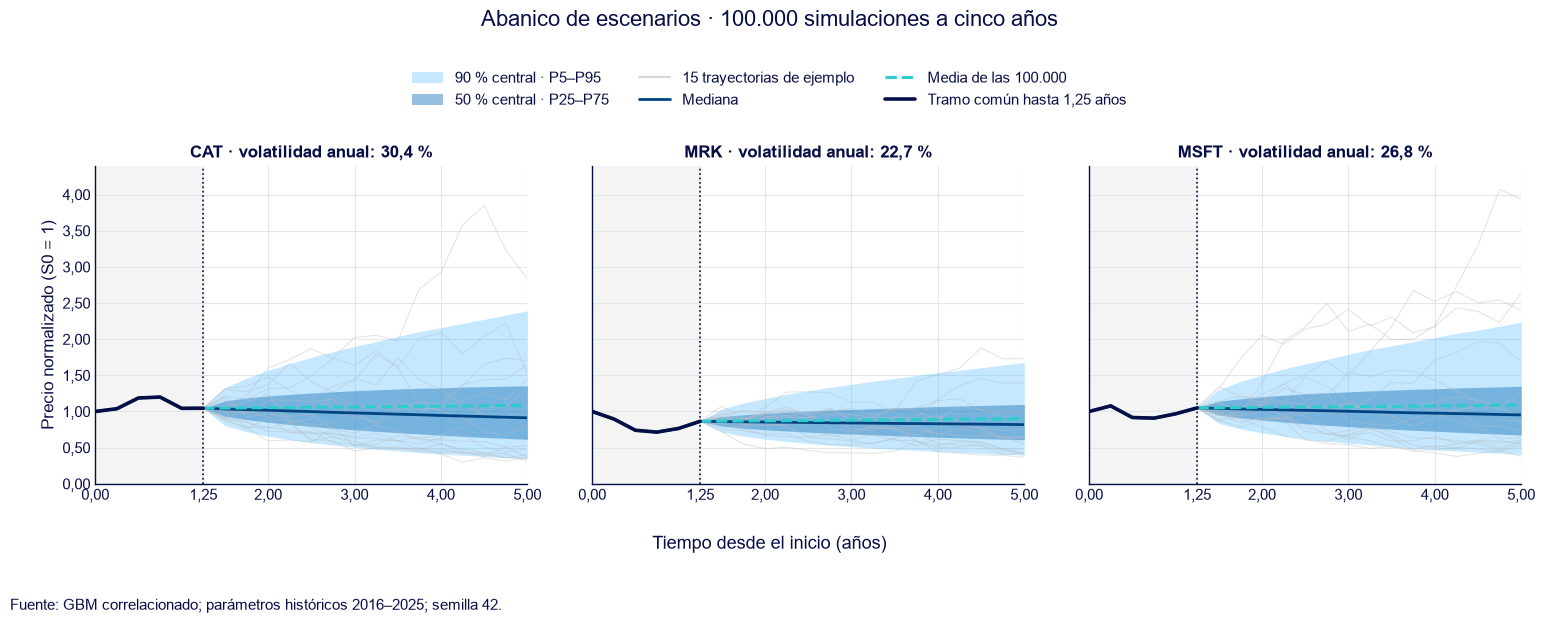

In [5]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

tiempos_abanico = np.r_[0, tiempos]
X_abanico = np.concatenate((np.broadcast_to(S0, (num_sims, 1, 3)), X), axis=1)
percentiles_abanico = np.percentile(X_abanico, [5, 25, 50, 75, 95], axis=0)
media_abanico = X_abanico.mean(axis=0)
indices_ejemplo = np.linspace(0, num_sims - 1, 15, dtype=int)
limite_y = max(percentiles_abanico[-1].max(), X_abanico[indices_ejemplo].max()) * 1.08
formato_abanico = plt.FuncFormatter(lambda valor, _: fmt_es(valor, 2))

fig_abanico, axes_abanico = plt.subplots(
    1, 3, figsize=(15.5, 6), sharey=True, facecolor=BBVA["blanco"]
)

def dibujar_abanico(ax, k):
    """Representa los cuantiles y ejemplos de un activo durante los cinco años."""
    ax.axvspan(0, t_bifurcacion, color=BBVA["gris"], zorder=0)
    ax.fill_between(tiempos_abanico, percentiles_abanico[0, :, k],
                    percentiles_abanico[4, :, k], color=BBVA["cielo"], alpha=0.35, linewidth=0)
    ax.fill_between(tiempos_abanico, percentiles_abanico[1, :, k],
                    percentiles_abanico[3, :, k], color=BBVA["medio"], alpha=0.45, linewidth=0)
    ax.plot(tiempos_abanico, X_abanico[indices_ejemplo, :, k].T,
            color=BBVA["gris_dato"], alpha=0.4, linewidth=0.8)
    ax.plot(tiempos_abanico, percentiles_abanico[2, :, k], color=BBVA["principal"], linewidth=2)
    ax.plot(tiempos_abanico, media_abanico[:, k], "--", color=BBVA["agua"], linewidth=2.2)
    ax.plot(tiempos_abanico[:n_pasos_comunes + 1],
            X_abanico[0, :n_pasos_comunes + 1, k], color=BBVA["marino"], linewidth=2.6)
    ax.axvline(t_bifurcacion, color=BBVA["marino"], linestyle=":", linewidth=1.2)
    ax.set_title(f"{activos[k]} · volatilidad anual: {fmt_es(100 * sigma[k], 1)} %",
                 fontsize=12, loc="center")
    ax.set(xlim=(0, TTM), ylim=(0, limite_y), xticks=[0, t_bifurcacion, 2, 3, 4, 5])
    ax.xaxis.set_major_formatter(formato_abanico)
    ax.yaxis.set_major_formatter(formato_abanico)

dibujar_abanico(axes_abanico[0], 0)
dibujar_abanico(axes_abanico[1], 1)
dibujar_abanico(axes_abanico[2], 2)
axes_abanico[0].set_ylabel("Precio normalizado (S0 = 1)")
fig_abanico.legend(handles=[
    Patch(facecolor=BBVA["cielo"], alpha=0.35, label="90 % central · P5–P95"),
    Patch(facecolor=BBVA["medio"], alpha=0.45, label="50 % central · P25–P75"),
    Line2D([], [], color=BBVA["gris_dato"], alpha=0.6, label="15 trayectorias de ejemplo"),
    Line2D([], [], color=BBVA["principal"], linewidth=2, label="Mediana"),
    Line2D([], [], color=BBVA["agua"], linestyle="--", linewidth=2.2, label="Media de las 100.000"),
    Line2D([], [], color=BBVA["marino"], linewidth=2.6, label="Tramo común hasta 1,25 años"),
], loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=3, frameon=False, labelcolor=BBVA["marino"], fontsize=11)
fig_abanico.suptitle("Abanico de escenarios · 100.000 simulaciones a cinco años", fontsize=16, y=0.99, color=BBVA["marino"])
fig_abanico.supxlabel("Tiempo desde el inicio (años)", y=0.085, color=BBVA["marino"])
fig_abanico.subplots_adjust(left=0.065, right=0.985, bottom=0.2, top=0.73, wspace=0.15)
cerrar_grafico(fig_abanico, "abanico_100000_cinco_anos", fuente=f"GBM correlacionado; parámetros históricos 2016–2025; semilla {semilla}.", ajustar_titulos=False)


## 4. Primeras cinco trayectorias y cierres anuales

La tabla recoge los precios normalizados de las primeras cinco simulaciones al cierre de los años **1, 2, 3, 4 y 5**. Las columnas **Simulación** y **Año** identifican cada observación. Estos años son tiempos relativos desde el inicio de la simulación, distintos de las fechas del histórico.

El gráfico representa un abanico de cinco trayectorias por activo, todas con origen en $S_0=1$ y con los mismos precios hasta el quinto paso, en $t=1,25$. Después se separan por los incrementos independientes de cada continuación. Se incluyen los 20 pasos trimestrales y el instante inicial. Por este motivo, los precios del cierre del año 1 son iguales entre simulaciones. Las primeras cinco trayectorias son ejemplos visuales; la valoración condicionada utiliza las 100.000 continuaciones.


In [6]:
df_precios_anuales = pd.DataFrame(
    X[:5, indices_anuales, :].reshape(25, 3),
    index=pd.MultiIndex.from_product(
        [simulaciones[:5], anios], names=["Simulación", "Año"]
    ),
    columns=activos,
).reset_index()
display(
    Markdown("**Primeras cinco simulaciones: precios normalizados al cierre de cada año**"),
    df_precios_anuales.round(4),
)


**Primeras cinco simulaciones: precios normalizados al cierre de cada año**

,Simulación,Año,CAT,MRK,MSFT
0,1,1,"1,043800","0,765400","0,967700"
1,1,2,"0,919200","0,992900","0,882900"
2,1,3,"1,074700","1,043600","1,120100"
3,1,4,"1,050600","1,150300","1,132200"
4,1,5,"1,445400","0,880600","1,259000"
5,2,1,"1,043800","0,765400","0,967700"
6,2,2,"0,815900","0,812400","1,184000"
7,2,3,"0,811700","0,681200","1,074100"
8,2,4,"0,654100","0,685600","0,901300"
9,2,5,"0,420500","0,485000","0,663900"


Guardado: Graficos\primeras_cinco_trayectorias.png


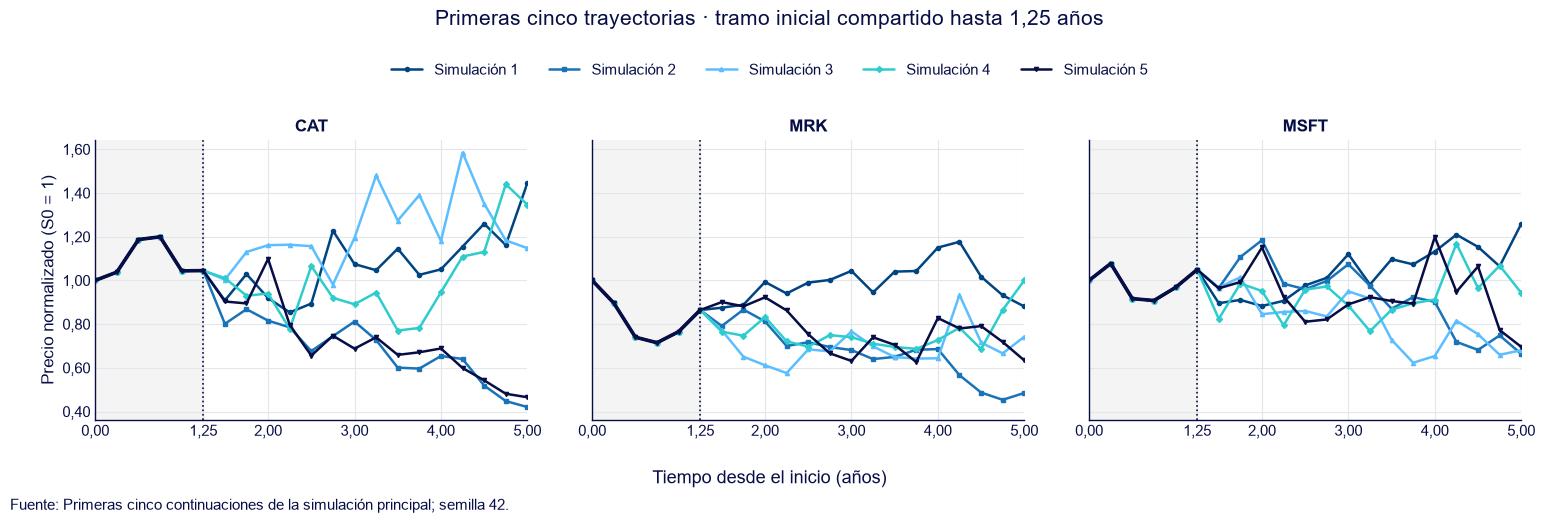

In [7]:
tiempos_con_t0 = np.r_[0, tiempos]
X_ejemplos = np.concatenate((np.broadcast_to(S0, (5, 1, 3)), X[:5]), axis=1)

fig_ejemplos, axes_ejemplos = plt.subplots(1, 3, figsize=(15.5, 5), sharey=True)

def dibujar_ejemplos(ax, k):
    """Dibuja las cinco primeras trayectorias de un activo y su tramo común."""
    ax.set_prop_cycle(color=PALETA, marker=["o", "s", "^", "D", "v"])
    ax.plot(tiempos_con_t0, X_ejemplos[:, :, k].T, linewidth=1.8, markersize=3)
    ax.axvspan(0, t_bifurcacion, color=BBVA["gris"], zorder=0)
    ax.plot(tiempos_con_t0[:n_pasos_comunes + 1],
            X_ejemplos[0, :n_pasos_comunes + 1, k], color=BBVA["marino"], linewidth=2.6, marker="")
    ax.axvline(t_bifurcacion, color=BBVA["marino"], linestyle=":", linewidth=1.2)
    ax.set_title(activos[k], fontsize=12, loc="center")
    ax.set(xlim=(0, TTM), xticks=[0, t_bifurcacion, 2, 3, 4, 5])
    ax.xaxis.set_major_formatter(formato_abanico)
    ax.yaxis.set_major_formatter(formato_abanico)

dibujar_ejemplos(axes_ejemplos[0], 0)
dibujar_ejemplos(axes_ejemplos[1], 1)
dibujar_ejemplos(axes_ejemplos[2], 2)
axes_ejemplos[0].set_ylabel("Precio normalizado (S0 = 1)")
fig_ejemplos.legend(axes_ejemplos[0].lines[:5],
    np.char.add("Simulación ", np.arange(1, 6).astype(str)),
    loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=5, frameon=False, labelcolor=BBVA["marino"])
fig_ejemplos.suptitle("Primeras cinco trayectorias · tramo inicial compartido hasta 1,25 años", fontsize=15, y=0.99, color=BBVA["marino"])
fig_ejemplos.supxlabel("Tiempo desde el inicio (años)", y=0.035, color=BBVA["marino"])
fig_ejemplos.subplots_adjust(left=0.065, right=0.985, bottom=0.17, top=0.73, wspace=0.15)
cerrar_grafico(fig_ejemplos, "primeras_cinco_trayectorias", fuente=f"Primeras cinco continuaciones de la simulación principal; semilla {semilla}.", ajustar_titulos=False)


### Muestra de 100 trayectorias y distribución terminal

Se seleccionan 100 trayectorias repartidas uniformemente entre las 100.000 simulaciones, sin volver a sortear escenarios. El tramo común se destaca y la media utiliza la muestra completa. Los histogramas terminales incluyen las 100.000 continuaciones; la línea discontinua indica la esperanza del precio final condicionada al tramo inicial.


Guardado: Graficos\mc_cien_trayectorias.png


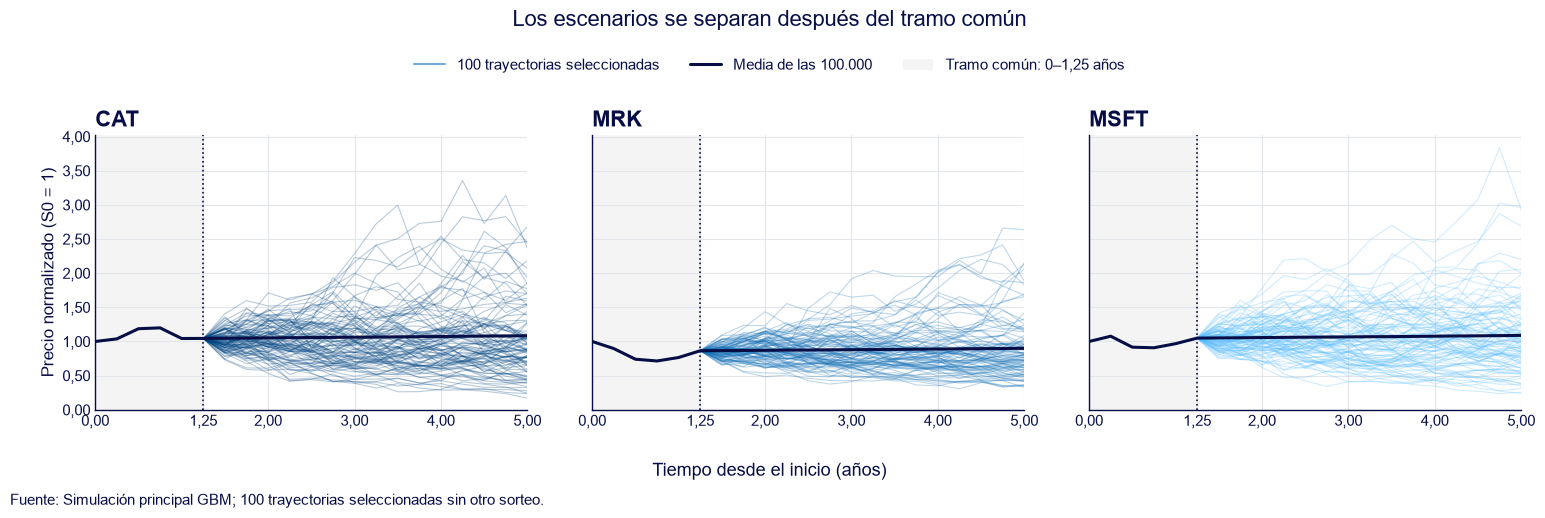

In [8]:
indices_cien = np.linspace(0, num_sims - 1, 100, dtype=int)
fig_cien, axes_cien = plt.subplots(1, 3, figsize=(15.5, 5), sharey=True)

def dibujar_cien(ax, k):
    """Muestra 100 trayectorias y la media de la muestra completa para un activo."""
    ax.axvspan(0, t_bifurcacion, color=BBVA["gris"], zorder=0)
    ax.plot(tiempos_abanico, X_abanico[indices_cien, :, k].T,
            color=PALETA[k], alpha=0.28, linewidth=0.8)
    ax.plot(tiempos_abanico, media_abanico[:, k], color=BBVA["marino"], linewidth=2.2)
    ax.axvline(t_bifurcacion, color=BBVA["marino"], linestyle=":", linewidth=1.2)
    ax.set(title=activos[k], xlim=(0, TTM), ylim=(0, X_abanico[indices_cien].max() * 1.05),
           xticks=[0, t_bifurcacion, 2, 3, 4, 5])
    ax.xaxis.set_major_formatter(formato_abanico)
    ax.yaxis.set_major_formatter(formato_abanico)

dibujar_cien(axes_cien[0], 0)
dibujar_cien(axes_cien[1], 1)
dibujar_cien(axes_cien[2], 2)
axes_cien[0].set_ylabel("Precio normalizado (S0 = 1)")
fig_cien.legend(handles=[
    Line2D([], [], color=BBVA["medio"], alpha=0.6, label="100 trayectorias seleccionadas"),
    Line2D([], [], color=BBVA["marino"], linewidth=2.2, label="Media de las 100.000"),
    Patch(facecolor=BBVA["gris"], label="Tramo común: 0–1,25 años"),
], loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=3)
fig_cien.suptitle("Los escenarios se separan después del tramo común", fontsize=16)
fig_cien.supxlabel("Tiempo desde el inicio (años)", y=0.04)
fig_cien.subplots_adjust(left=0.065, right=0.985, bottom=0.18, top=0.73, wspace=0.15)
cerrar_grafico(fig_cien, "mc_cien_trayectorias", fuente="Simulación principal GBM; 100 trayectorias seleccionadas sin otro sorteo.", ajustar_titulos=False)


Guardado: Graficos\mc_precios_finales.png


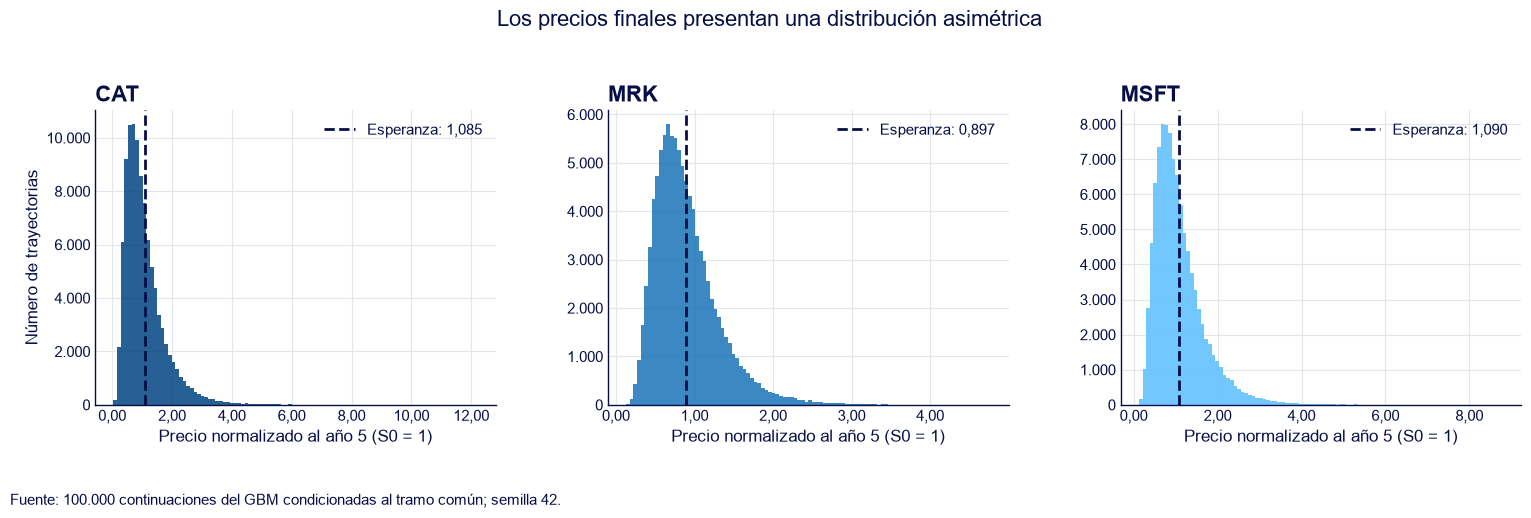

In [9]:
fig_terminal, axes_terminal = plt.subplots(1, 3, figsize=(15.5, 5))

def dibujar_terminal(ax, k):
    """Representa todos los precios finales de un activo y su esperanza condicionada."""
    esperanza = X[0, n_pasos_comunes - 1, k] * np.exp(r * (TTM - t_bifurcacion))
    ax.hist(X[:, -1, k], bins=100, color=PALETA[k], alpha=0.85)
    ax.axvline(esperanza, color=BBVA["marino"], linestyle="--", linewidth=2,
               label=f"Esperanza: {fmt_es(esperanza, 3)}")
    ax.set(title=activos[k], xlabel="Precio normalizado al año 5 (S0 = 1)")
    ax.xaxis.set_major_formatter(formato_abanico)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor)))
    ax.legend(loc="upper right")

dibujar_terminal(axes_terminal[0], 0)
dibujar_terminal(axes_terminal[1], 1)
dibujar_terminal(axes_terminal[2], 2)
axes_terminal[0].set_ylabel("Número de trayectorias")
fig_terminal.suptitle("Los precios finales presentan una distribución asimétrica", fontsize=16)
fig_terminal.subplots_adjust(left=0.065, right=0.985, bottom=0.19, top=0.78, wspace=0.28)
cerrar_grafico(fig_terminal, "mc_precios_finales", fuente="100.000 continuaciones del GBM condicionadas al tramo común; semilla 42.", ajustar_titulos=False)


## 5. Cálculo del payoff y valoración condicionada

La opción es asiática porque su pago depende de los precios observados durante la trayectoria. Para cada simulación se calcula la media geométrica de los **20 precios normalizados** de cada activo, incluidos los cinco pasos comunes, y después se suman las tres medias:

$$
G_k=\exp\left(\frac{1}{20}\sum_{j=1}^{20}
\ln\frac{S_j^k}{S_0^k}\right),
\qquad
V_T=\max(G_1+G_2+G_3-3,0).
$$

La media se toma **a lo largo del tiempo para cada activo**, no entre los tres activos en un mismo instante. La parte positiva del resultado aplica el strike 3 y garantiza un payoff no negativo. Los payoffs de cero también se incluyen en la valoración.

Al fijar la historia común $H$ hasta $t_c=1,25$, las 100.000 continuaciones estiman el pago esperado **condicionado a esa historia**. La prima en el final del tramo común se obtiene mediante:

$$
\widehat V_{t_c\mid H}=e^{-r(T-t_c)}
\frac{1}{N}\sum_{h=1}^{N}V_T^{(h)}.
$$

También se muestra la media descontada a $t=0$, $e^{-rT}\overline V_T$. Es un resultado condicionado al tramo elegido, **no una prima inicial incondicional**, porque no se promedian posibles historias distintas de los cinco primeros pasos.

El resumen incluye ambos valores, el payoff medio, los porcentajes de pagos positivos y nulos y el error estándar de la media descontada a $t=0$. Ese error cuantifica el muestreo de las continuaciones, manteniendo fijo el tramo común.


In [10]:
medias_geometricas = np.exp(np.mean(np.log(X / S0), axis=1))
payoff = np.maximum(medias_geometricas.sum(axis=1) - strike, 0)
primas_t0 = payoff * np.exp(-r * TTM)
prima_t0 = primas_t0.mean()
prima_bifurcacion = payoff.mean() * np.exp(-r * (TTM - t_bifurcacion))
error_estandar = primas_t0.std(ddof=1) / np.sqrt(num_sims)

df_payoffs = pd.DataFrame(
    medias_geometricas, index=simulaciones,
    columns=np.char.add("Media geométrica ", np.asarray(activos)),
)
df_payoffs["Suma de medias"] = medias_geometricas.sum(axis=1)
df_payoffs["Payoff final"] = payoff
df_payoffs["Payoff descontado a t=0"] = primas_t0
display(Markdown("**Payoffs de las primeras cinco continuaciones**"), df_payoffs.head(5).round(6))

df_resumen = pd.DataFrame({
    "Resultado": [
        "Media descontada a t=0 (tramo común fijado)",
        "Prima condicionada en t=1,25 años",
        "Payoff medio al vencimiento",
        "Payoff positivo (%)", "Payoff cero (%)",
        "Error estándar de la media descontada a t=0",
    ],
    "Valor": [
        prima_t0, prima_bifurcacion, payoff.mean(),
        100 * (payoff > 0).mean(), 100 * (payoff == 0).mean(), error_estandar,
    ],
})
display(Markdown("**Resumen de las 100.000 continuaciones con el mismo tramo inicial**"), df_resumen.round(6))


**Payoffs de las primeras cinco continuaciones**

,Media geométrica CAT,Media geométrica MRK,Media geométrica MSFT,Suma de medias,Payoff final,Payoff descontado a t=0
Simulación,,,,,,
1,"1,076804","0,937171","1,024081","3,038057","0,038057","0,036200"
2,"0,749549","0,683181","0,922822","2,355552","0,000000","0,000000"
3,"1,185601","0,714959","0,843356","2,743915","0,000000","0,000000"
4,"1,011893","0,765476","0,938971","2,716339","0,000000","0,000000"
5,"0,776183","0,765510","0,936164","2,477857","0,000000","0,000000"


**Resumen de las 100.000 continuaciones con el mismo tramo inicial**

,Resultado,Valor
0,Media descontada a t=0 (tramo común fijado),"0,154328"
1,"Prima condicionada en t=1,25 años","0,156269"
2,Payoff medio al vencimiento,"0,162241"
3,Payoff positivo (%),"38,908000"
4,Payoff cero (%),"61,092000"
5,Error estándar de la media descontada a t=0,"0,000905"


## 6. Payoffs descontados por fecha: matriz Y

El valor descontado de cada trayectoria en un instante se obtiene descontando su payoff final hasta esa fecha:

$$
t_j=j\Delta t,\qquad
Y_{h,j}=V_T^{(h)}e^{-r(20-j)\Delta t}
       =V_T^{(h)}e^{-r(T-t_j)}.
$$

El código utiliza tiempos expresados en años. Por ello, **TTM - tiempos** ya es el tiempo restante hasta el vencimiento y no se vuelve a multiplicar por $\Delta t$.

**Y** tiene forma **(100000, 20)**. La fila $h$ mantiene la correspondencia con la trayectoria $h$ de X y la columna $j$ corresponde al mismo instante trimestral. En el vencimiento, $Y_{h,20}=V_T^{(h)}$.

**df_primas** conserva las 20 fechas y todas las simulaciones. **df_primas_trimestrales** muestra la media y el error estándar de Y en cada una de esas fechas. **df_primas_anuales** muestra el valor descontado en $t=0$ y los cinco cierres anuales de las primeras cinco trayectorias, junto con la media de las 100.000 simulaciones.

Cada elemento de Y es un **payoff realizado descontado**. La media en $t=0$ es el pago esperado condicionado al tramo común, descontado al origen. En $t=1,25$, la media de Y coincide con la prima condicionada al final de ese tramo. La evolución por fecha de una trayectoria refleja únicamente el descuento de su mismo payoff final: no representa una revaloración con nueva información en cada fecha.

Aunque los precios iniciales sean compartidos, los payoffs y los elementos de Y pueden ser distintos, porque dependen también de los 15 pasos posteriores.


In [11]:
Y = payoff[:, None] * np.exp(-r * (TTM - tiempos))[None, :]
df_primas = pd.DataFrame(
    Y, index=simulaciones, columns=pd.Index(tiempos, name="Año")
)

df_primas_anuales = pd.DataFrame(
    np.vstack((primas_t0[:5], Y[:5, indices_anuales].T)),
    index=pd.Index(np.r_[0, anios], name="Año"),
    columns=np.char.add("Simulación ", np.arange(1, 6).astype(str)),
)
df_primas_anuales["Media de 100.000"] = np.r_[
    prima_t0, Y[:, indices_anuales].mean(axis=0)
]
display(Markdown("**Payoffs descontados por fecha: inicio y cierre de cada año**"), df_primas_anuales.round(6))

df_primas_trimestrales = pd.DataFrame({
    "Tiempo (años)": tiempos,
    "Media del payoff descontado": Y.mean(axis=0),
    "Error estándar": Y.std(axis=0, ddof=1) / np.sqrt(num_sims),
})
display(Markdown("**Las 20 fechas trimestrales: medias condicionadas al tramo común**"),
        df_primas_trimestrales.round(6))


**Payoffs descontados por fecha: inicio y cierre de cada año**

,Simulación 1,Simulación 2,Simulación 3,Simulación 4,Simulación 5,Media de 100.000
Año,,,,,,
0,"0,036200","0,000000","0,000000","0,000000","0,000000","0,154328"
1,"0,036564","0,000000","0,000000","0,000000","0,000000","0,155879"
2,"0,036932","0,000000","0,000000","0,000000","0,000000","0,157446"
3,"0,037303","0,000000","0,000000","0,000000","0,000000","0,159028"
4,"0,037678","0,000000","0,000000","0,000000","0,000000","0,160626"
5,"0,038057","0,000000","0,000000","0,000000","0,000000","0,162241"


**Las 20 fechas trimestrales: medias condicionadas al tramo común**

,Tiempo (años),Media del payoff descontado,Error estándar
0,"0,250000","0,154714","0,000908"
1,"0,500000","0,155102","0,000910"
2,"0,750000","0,155490","0,000912"
3,"1,000000","0,155879","0,000914"
4,"1,250000","0,156269","0,000917"
5,"1,500000","0,156660","0,000919"
6,"1,750000","0,157052","0,000921"
7,"2,000000","0,157446","0,000924"
8,"2,250000","0,157840","0,000926"
9,"2,500000","0,158235","0,000928"


## 7. Distribución de los payoffs positivos

Se representan solo los payoffs **mayores que cero**, para que la masa de ceros no oculte su distribución. El título indica el porcentaje de simulaciones con payoff cero; el resumen anterior muestra ambos porcentajes. Los ceros **sí se incluyen** al calcular la prima media.


Guardado: Graficos\distribucion_payoffs_positivos.png


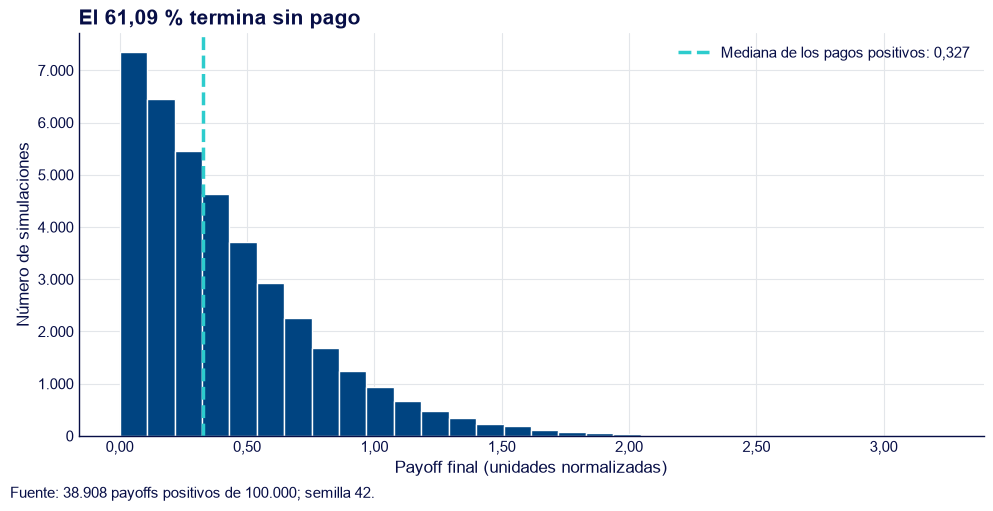

In [12]:
payoffs_positivos = payoff[payoff > 0]
mediana_positivos = np.median(payoffs_positivos)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(payoffs_positivos, bins=30, color=BBVA["principal"], edgecolor=BBVA["blanco"])
ax.axvline(mediana_positivos, color=BBVA["agua"], linewidth=2.5, linestyle="--",
           label=f"Mediana de los pagos positivos: {fmt_es(mediana_positivos, 3)}")
ax.set_xlabel("Payoff final (unidades normalizadas)")
ax.set_ylabel("Número de simulaciones")
ax.set_title(
    f"El {fmt_es(100 * (payoff == 0).mean(), 2)} % termina sin pago",
    fontsize=15, loc="left",
)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor, 2)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor)))
ax.legend(labelcolor=BBVA["marino"])
fig.tight_layout()
cerrar_grafico(fig, "distribucion_payoffs_positivos", fuente=f"{fmt_es(payoffs_positivos.size)} payoffs positivos de 100.000; semilla {semilla}.", ajustar_titulos=False)


## 8. Validación de la simulación principal

Se comprueban las dimensiones y la correspondencia entre X, payoff e Y, la reproducción exacta del tramo común y la factorización de Cholesky.

La correlación se calcula sobre los **incrementos logarítmicos de los 15 pasos posteriores**, sin contar las 100.000 repeticiones del tramo común como observaciones aleatorias independientes. La tabla contrasta la matriz simulada con la matriz histórica; la tolerancia de comprobación es 0,01 en correlación absoluta.

La media terminal se compara con la esperanza neutral al riesgo **condicionada al precio del final del tramo común**:

$$
E[S_T^k\mid H]=S_{1,25}^k\,e^{r(5-1,25)}.
$$

La desviación se expresa en errores estándar de la media terminal. Una diferencia inferior a cinco errores estándar se utiliza como comprobación de compatibilidad de Monte Carlo, no como garantía del modelo.


In [13]:
comprobaciones = np.array([
    X.shape == (num_sims, num_pasos, len(activos)),
    Y.shape == (num_sims, num_pasos),
    np.all(X[:, :n_pasos_comunes, :] == X[0, :n_pasos_comunes, :]),
    np.all(np.ptp(X[:, n_pasos_comunes, :], axis=0) > 0),
    np.array_equal(Y[:, -1], payoff),
    np.allclose(rho, rho.T),
    np.allclose(L @ L.T, rho),
])
df_validacion = pd.DataFrame({
    "Comprobación": [
        "Dimensiones de X", "Dimensiones de Y", "Cinco pasos iniciales idénticos",
        "Continuaciones distintas tras el tramo común", "Y al vencimiento coincide con el payoff",
        "Matriz rho simétrica", "Cholesky: L @ L.T reproduce rho",
    ],
    "Resultado": np.where(comprobaciones, "Correcto", "No cumple"),
})
assert comprobaciones.all(), "Revisar la estructura de la simulación."

correlacion_simulada = np.corrcoef(
    incrementos[:, n_pasos_comunes:, :].reshape(-1, len(activos)), rowvar=False
)
df_correlacion_simulada = pd.DataFrame({
    "Activo 1": np.repeat(activos, len(activos)),
    "Activo 2": np.tile(activos, len(activos)),
    "Correlación objetivo": rho.ravel(),
    "Correlación simulada": correlacion_simulada.ravel(),
    "Diferencia": (correlacion_simulada - rho).ravel(),
})
assert np.max(np.abs(correlacion_simulada - rho)) < 0.01, "Revisar las correlaciones."

media_terminal = X[:, -1, :].mean(axis=0)
media_terminal_teorica = X[0, n_pasos_comunes - 1, :] * np.exp(r * (TTM - t_bifurcacion))
ee_terminal = X[:, -1, :].std(axis=0, ddof=1) / np.sqrt(num_sims)
desviacion_terminal = (media_terminal - media_terminal_teorica) / ee_terminal
df_media_terminal = pd.DataFrame({
    "Activo": activos, "Media simulada": media_terminal,
    "Esperanza condicionada": media_terminal_teorica,
    "Error estándar": ee_terminal, "Desviación (errores estándar)": desviacion_terminal,
    "Compatible (< 5 EE)": np.abs(desviacion_terminal) < 5,
})
assert np.all(np.abs(desviacion_terminal) < 5), "Revisar la media terminal condicionada."

display(Markdown("**Comprobaciones estructurales**"), df_validacion)
display(Markdown("**Correlaciones de los incrementos posteriores al tramo común**"),
        df_correlacion_simulada.round(6))
display(Markdown("**Precios terminales: simulación frente a esperanza condicionada**"),
        df_media_terminal.round(6))


**Comprobaciones estructurales**

,Comprobación,Resultado
0,Dimensiones de X,Correcto
1,Dimensiones de Y,Correcto
2,Cinco pasos iniciales idénticos,Correcto
3,Continuaciones distintas tras el tramo común,Correcto
4,Y al vencimiento coincide con el payoff,Correcto
5,Matriz rho simétrica,Correcto
6,Cholesky: L @ L.T reproduce rho,Correcto


**Correlaciones de los incrementos posteriores al tramo común**

,Activo 1,Activo 2,Correlación objetivo,Correlación simulada,Diferencia
0,CAT,CAT,"1,000000","1,000000","-0,000000"
1,CAT,MRK,"0,249833","0,250329","0,000496"
2,CAT,MSFT,"0,394764","0,394277","-0,000487"
3,MRK,CAT,"0,249833","0,250329","0,000496"
4,MRK,MRK,"1,000000","1,000000","0,000000"
5,MRK,MSFT,"0,276564","0,275926","-0,000638"
6,MSFT,CAT,"0,394764","0,394277","-0,000487"
7,MSFT,MRK,"0,276564","0,275926","-0,000638"
8,MSFT,MSFT,"1,000000","1,000000","-0,000000"


**Precios terminales: simulación frente a esperanza condicionada**

,Activo,Media simulada,Esperanza condicionada,Error estándar,Desviación (errores estándar),Compatible (< 5 EE)
0,CAT,"1,083704","1,084685","0,002203","-0,445276",True
1,MRK,"0,899588","0,897447","0,001308","1,636955",True
2,MSFT,"1,089124","1,089523","0,001906","-0,209284",True


### Distribución de los retornos simulados

Se muestran los incrementos logarítmicos trimestrales de los **15 pasos posteriores al tramo común**, con 1.500.000 observaciones por activo. Se excluyen los cinco pasos fijados para no contar repetidamente el mismo sorteo. En el GBM su distribución marginal es normal, con media $(r-\sigma_k^2/2)\Delta t$ y desviación $\sigma_k\sqrt{\Delta t}$. La curva contrasta estos parámetros con el histograma; las correlaciones entre activos se comprueban por separado.


Guardado: Graficos\mc_retornos_simulados.png


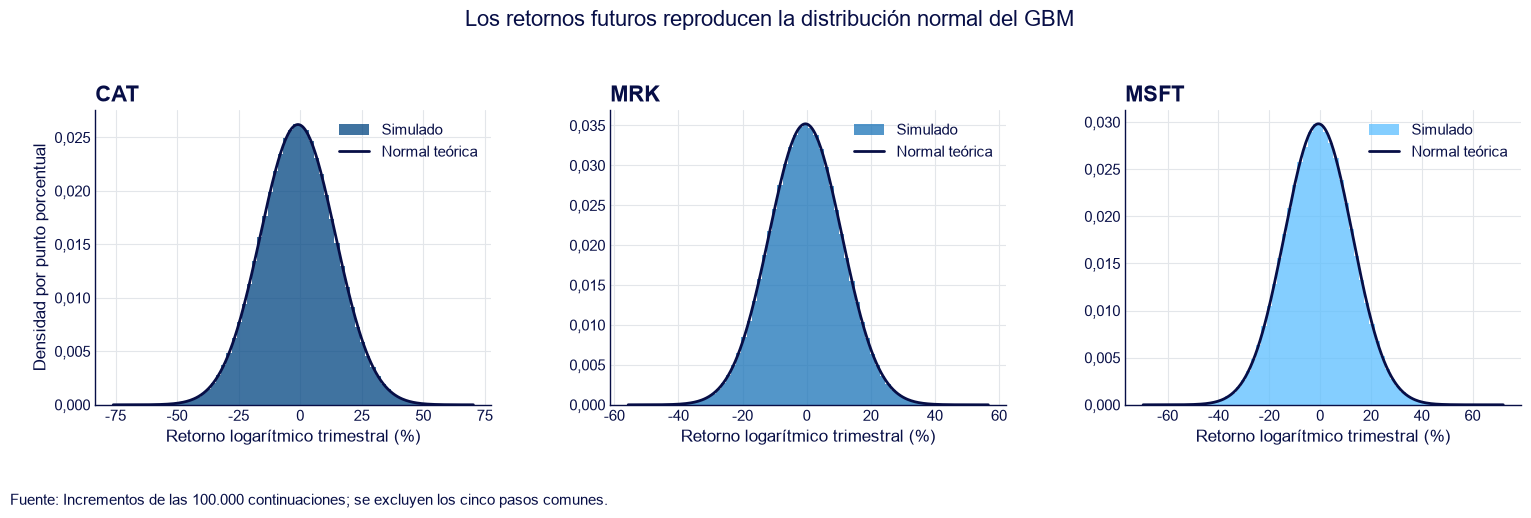

In [14]:
fig_retornos, axes_retornos = plt.subplots(1, 3, figsize=(15.5, 5))

def dibujar_retornos(ax, k):
    """Compara los retornos futuros simulados con su densidad normal teórica."""
    valores = 100 * incrementos[:, n_pasos_comunes:, k].ravel()
    mu = 100 * (r - 0.5 * sigma[k]**2) * dt
    desviacion = 100 * sigma[k] * np.sqrt(dt)
    rejilla = np.linspace(valores.min(), valores.max(), 300)
    densidad = np.exp(-0.5 * ((rejilla - mu) / desviacion)**2) / (desviacion * np.sqrt(2 * np.pi))
    ax.hist(valores, bins=70, density=True, color=PALETA[k], alpha=0.75, label="Simulado")
    ax.plot(rejilla, densidad, color=BBVA["marino"], linewidth=2, label="Normal teórica")
    ax.set(title=activos[k], xlabel="Retorno logarítmico trimestral (%)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor)))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor, 3)))
    ax.legend()

dibujar_retornos(axes_retornos[0], 0)
dibujar_retornos(axes_retornos[1], 1)
dibujar_retornos(axes_retornos[2], 2)
axes_retornos[0].set_ylabel("Densidad por punto porcentual")
fig_retornos.suptitle("Los retornos futuros reproducen la distribución normal del GBM", fontsize=16)
fig_retornos.subplots_adjust(left=0.065, right=0.985, bottom=0.19, top=0.78, wspace=0.3)
cerrar_grafico(fig_retornos, "mc_retornos_simulados", fuente="Incrementos de las 100.000 continuaciones; se excluyen los cinco pasos comunes.", ajustar_titulos=False)


## 9. Referencia con trayectorias independientes

La simulación principal conserva sus cinco pasos iniciales comunes. Como contraste, se genera otra muestra de **100.000 trayectorias con los 20 pasos independientes entre simulaciones**, manteniendo el mismo modelo, parámetros, fechas de observación y payoff. Se reinicia un generador separado con semilla 42, sin modificar X, Y ni el generador principal.

La referencia estima una **prima inicial incondicional**: también promedia posibles historias de los primeros cinco pasos. La simulación principal estima una valoración **condicionada a una historia concreta**, descontada a $t=0$. Por ello, sus cifras no deben interpretarse como dos estimadores del mismo valor.

El error estándar de la versión principal solo mide el ruido de las continuaciones. No mide cuánto cambiaría el resultado al escoger otro tramo común, ni la incertidumbre de los parámetros históricos. Una semilla asegura reproducibilidad, no una valoración más correcta.

Ambos diseños se reproducen con la semilla 42 en generadores separados que comienzan con la misma secuencia: las dos muestras no son independientes entre sí. La independencia de la referencia se refiere a sus trayectorias entre sí, no a una segunda fuente aleatoria distinta.


In [15]:
rng_referencia = np.random.default_rng(semilla)
Z_referencia = rng_referencia.standard_normal((num_sims, num_pasos, len(activos))) @ L.T
incrementos_referencia = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z_referencia
X_referencia = S0 * np.exp(np.cumsum(incrementos_referencia, axis=1))
G_referencia = np.exp(np.log(X_referencia / S0).mean(axis=1))
payoff_referencia = np.maximum(G_referencia.sum(axis=1) - strike, 0)
descontados_referencia = payoff_referencia * np.exp(-r * TTM)
prima_referencia = descontados_referencia.mean()
ee_referencia = descontados_referencia.std(ddof=1) / np.sqrt(num_sims)

df_comparacion = pd.DataFrame({
    "Diseño": ["Principal: cinco pasos comunes", "Referencia: veinte pasos independientes"],
    "Valoración": ["Condicionada al tramo común", "Incondicional"],
    "Trayectorias": [num_sims, num_sims],
    "Media descontada a t=0": [prima_t0, prima_referencia],
    "Error estándar": [error_estandar, ee_referencia],
    "Payoff medio": [payoff.mean(), payoff_referencia.mean()],
    "Payoff positivo (%)": [100 * (payoff > 0).mean(), 100 * (payoff_referencia > 0).mean()],
})
display(Markdown("**Comparación: el tramo fijado cambia la valoración estimada**"), df_comparacion.round(6))


**Comparación: el tramo fijado cambia la valoración estimada**

,Diseño,Valoración,Trayectorias,Media descontada a t=0,Error estándar,Payoff medio,Payoff positivo (%)
0,Principal: cinco pasos comunes,Condicionada al tramo común,100000,"0,154328","0,000905","0,162241","38,908000"
1,Referencia: veinte pasos independientes,Incondicional,100000,"0,295072","0,001624","0,310201","44,129000"


### Validación de los precios descontados

Bajo la medida neutral al riesgo y sin dividendos, $E[e^{-rT}S_T^k]=S_0^k$. Se comprueba esta identidad con la muestra de **20 pasos independientes** y una tolerancia relativa del 1 %. La muestra principal se compara con su esperanza **condicionada** en la validación anterior: no debe contrastarse con $S_0$ después de fijar una historia inicial.


In [16]:
terminal_descontado = X_referencia[:, -1, :] * np.exp(-r * TTM)
media_martingala = terminal_descontado.mean(axis=0)
error_martingala = np.abs(media_martingala / S0 - 1)
df_martingala = pd.DataFrame({
    "Activo": activos, "Precio inicial": S0,
    "Media del precio terminal descontado": media_martingala,
    "Error estándar": terminal_descontado.std(axis=0, ddof=1) / np.sqrt(num_sims),
    "Error relativo (%)": 100 * error_martingala,
    "Error inferior al 1 %": error_martingala < 0.01,
})
assert np.all(error_martingala < 0.01), "Revisar la esperanza de los precios descontados."
display(Markdown("**Precios descontados: referencia independiente frente a S0**"),
        df_martingala.round(6))


**Precios descontados: referencia independiente frente a S0**

,Activo,Precio inicial,Media del precio terminal descontado,Error estándar,Error relativo (%),Error inferior al 1 %
0,CAT,"1,000000","0,998444","0,002407","0,155624",True
1,MRK,"1,000000","1,003097","0,001711","0,309661",True
2,MSFT,"1,000000","1,000479","0,002069","0,047880",True


## 10. Contraste analítico auxiliar: asiática geométrica de CAT

Se comprueba una call geométrica sobre **CAT únicamente**, con precio inicial normalizado a 1, strike auxiliar 1 y las mismas 20 observaciones trimestrales, sin incluir $t=0$. Se utiliza la muestra independiente de la sección anterior: la fórmula incondicional no se aplica a las trayectorias con tramo fijado.

Para $n=20$, la media logarítmica tiene media $m$ y varianza $v$:

$$
m=(r-\sigma^2/2)\Delta t\frac{n+1}{2},
\qquad
v=\sigma^2\Delta t\frac{(n+1)(2n+1)}{6n}.
$$

La fórmula geométrica discreta se obtiene de esa distribución lognormal:

$$
C_0=e^{-rT}\left[e^{m+v/2}\Phi(d_1)-\Phi(d_2)\right],
\qquad
d_2=\frac{m}{\sqrt v},\quad d_1=d_2+\sqrt v.
$$

$\Phi$ es la función de distribución normal estándar. La diferencia entre Monte Carlo y la fórmula se expresa en errores estándar. El strike 1 solo pertenece a este contraste auxiliar: **la cesta principal mantiene strike 3 y no se modifica**. La fórmula de un solo activo no valora la suma de las tres medias geométricas.

Referencia matemática: [opción asiática geométrica con observación discreta](https://wanghemath.github.io/Book-MathFinance/chapters/chapter-23-exotic-options.html#discrete-geometric-asian-option-under-blackscholes).


In [17]:
from math import erf

def normal_acumulada(z):
    """Devuelve la probabilidad acumulada normal estándar de un valor escalar."""
    return 0.5 * (1 + erf(z / np.sqrt(2)))

sigma_cat = sigma[0]
m_geometrica = (r - 0.5 * sigma_cat**2) * dt * (num_pasos + 1) / 2
v_geometrica = sigma_cat**2 * dt * (num_pasos + 1) * (2 * num_pasos + 1) / (6 * num_pasos)
d2 = m_geometrica / np.sqrt(v_geometrica)
d1 = d2 + np.sqrt(v_geometrica)
prima_analitica = np.exp(-r * TTM) * (
    np.exp(m_geometrica + 0.5 * v_geometrica) * normal_acumulada(d1) - normal_acumulada(d2)
)

pagos_cat_descontados = np.maximum(G_referencia[:, 0] - 1, 0) * np.exp(-r * TTM)
prima_cat_mc = pagos_cat_descontados.mean()
ee_cat = pagos_cat_descontados.std(ddof=1) / np.sqrt(num_sims)
diferencia_cat = prima_cat_mc - prima_analitica
df_validacion_asiatica = pd.DataFrame({
    "Activo": ["CAT"], "Strike auxiliar": [1],
    "Prima Monte Carlo": [prima_cat_mc], "Prima analítica discreta": [prima_analitica],
    "Error estándar MC": [ee_cat], "Diferencia MC - analítica": [diferencia_cat],
    "Diferencia (errores estándar)": [diferencia_cat / ee_cat],
    "Compatible (< 5 EE)": [abs(diferencia_cat) < 5 * ee_cat],
})
assert abs(diferencia_cat) < 5 * ee_cat, "Revisar el contraste asiático de un solo activo."
display(Markdown("**Validación auxiliar de CAT: Monte Carlo frente a fórmula cerrada**"),
        df_validacion_asiatica.round(6))


**Validación auxiliar de CAT: Monte Carlo frente a fórmula cerrada**

,Activo,Strike auxiliar,Prima Monte Carlo,Prima analítica discreta,Error estándar MC,Diferencia MC - analítica,Diferencia (errores estándar),Compatible (< 5 EE)
0,CAT,1,"0,146487","0,146999","0,000890","-0,000512","-0,575167",True


## 11. Fórmula cerrada aproximada para la cesta

Cada media geométrica temporal $G_i$ es lognormal. La cesta $B=G_1+G_2+G_3$ es una suma de lognormales correlacionadas y **no es, en general, lognormal**. Se aproxima su distribución por una lognormal con los mismos dos primeros momentos. Este contraste conserva el payoff $(B-3)^+$ y no sustituye la estimación de Monte Carlo.

Si hay $k$ precios iniciales fijados, quedan $q=20-k$ pasos. Con $\ell_{j,i}=\log(S_{j,i}/S_{0,i})$, $\ell_{0,i}=0$ y $n=20$:

$$
m_i=E[\log G_i\mid H_k]
=\frac{\sum_{j=1}^{k}\ell_{j,i}+q\ell_{k,i}
+(r-\sigma_i^2/2)\Delta t\,q(q+1)/2}{n},
$$

$$
C_{ij}=\operatorname{Cov}(\log G_i,\log G_j\mid H_k)
=\rho_{ij}\sigma_i\sigma_j\Delta t\,
\frac{q(q+1)(2q+1)}{6n^2}.
$$

Para la referencia incondicional se utiliza $k=0$. Los momentos **exactos** de la cesta son:

$$
a_i=e^{m_i+C_{ii}/2},\qquad
M_1=\sum_i a_i,\qquad M_2=\sum_{i,j}a_i a_j e^{C_{ij}}.
$$

La aproximación lognormal tiene varianza logarítmica $v_B=\log(M_2/M_1^2)$. Su fórmula de valoración es:

$$
\widehat V_t=e^{-r(T-t)}[M_1\Phi(d_1)-K\Phi(d_2)],
\qquad
d_1=\frac{\log(M_1/K)+v_B/2}{\sqrt{v_B}},\quad
d_2=d_1-\sqrt{v_B}.
$$

El ajuste de momentos para cestas se describe en [Brigo et al. (2002)](https://www.ma.imperial.ac.uk/~dbrigo/basketkli.pdf). Aquí los momentos se obtienen para las medias geométricas discretas y, en el caso principal, condicionados a la historia compartida. La fórmula es **aproximada para la cesta**, no una expresión exacta ni una fórmula específica facilitada por BBVA. La diferencia frente a Monte Carlo puede incluir tanto ruido de simulación como sesgo de aproximación.


In [18]:
def momentos_geometricos(historia=None):
    """Calcula la media y covarianza exactas de log(G), con historia opcional."""
    if historia is None:
        log_historia = np.empty((0, len(activos)))
        ultimo = np.zeros(len(activos))
    else:
        log_historia = np.log(historia / S0)
        ultimo = log_historia[-1]
    pendientes = num_pasos - log_historia.shape[0]
    m = (log_historia.sum(axis=0) + pendientes * ultimo
         + (r - 0.5 * sigma**2) * dt * pendientes * (pendientes + 1) / 2) / num_pasos
    C = (rho * np.outer(sigma, sigma) * dt
         * pendientes * (pendientes + 1) * (2 * pendientes + 1) / (6 * num_pasos**2))
    return m, C

def precio_cesta_momentos(m, C, tiempo=0, ejercicio=strike):
    """Aproxima la call sobre la suma de G ajustando dos momentos lognormales."""
    medias = np.exp(m + 0.5 * np.diag(C))
    M1 = medias.sum()
    M2 = (np.outer(medias, medias) * np.exp(C)).sum()
    varianza_log = max(np.log(M2 / M1**2), 0.0)
    if varianza_log == 0:
        return np.exp(-r * (TTM - tiempo)) * max(M1 - ejercicio, 0)
    raiz = np.sqrt(varianza_log)
    d1_cesta = (np.log(M1 / ejercicio) + 0.5 * varianza_log) / raiz
    d2_cesta = d1_cesta - raiz
    return np.exp(-r * (TTM - tiempo)) * (
        M1 * normal_acumulada(d1_cesta) - ejercicio * normal_acumulada(d2_cesta)
    )

m_condicionado, C_condicionado = momentos_geometricos(X[0, :n_pasos_comunes, :])
m_independiente, C_independiente = momentos_geometricos()
prima_aprox_condicionada = precio_cesta_momentos(m_condicionado, C_condicionado)
prima_aprox_bifurcacion = precio_cesta_momentos(
    m_condicionado, C_condicionado, tiempo=t_bifurcacion
)
prima_aprox_independiente = precio_cesta_momentos(m_independiente, C_independiente)

df_cesta_aproximada = pd.DataFrame({
    "Diseño": ["Tramo común, descuento a t=0", "Tramo común, prima en t=1,25", "Independiente, prima en t=0"],
    "Monte Carlo": [prima_t0, prima_bifurcacion, prima_referencia],
    "Fórmula aproximada": [prima_aprox_condicionada, prima_aprox_bifurcacion, prima_aprox_independiente],
    "Error estándar MC": [error_estandar, error_estandar * np.exp(r * t_bifurcacion), ee_referencia],
})
df_cesta_aproximada["Aproximación - MC"] = (
    df_cesta_aproximada["Fórmula aproximada"] - df_cesta_aproximada["Monte Carlo"]
)
df_cesta_aproximada["Diferencia relativa (%)"] = (
    100 * df_cesta_aproximada["Aproximación - MC"] / df_cesta_aproximada["Monte Carlo"]
)
assert np.isclose(precio_cesta_momentos(
    m_independiente[:1], C_independiente[:1, :1], ejercicio=1
), prima_analitica), "La fórmula de un activo debe coincidir con el contraste exacto de CAT."
display(Markdown("**Cesta de tres activos: Monte Carlo frente a ajuste lognormal de dos momentos**"),
        df_cesta_aproximada.round(6))


**Cesta de tres activos: Monte Carlo frente a ajuste lognormal de dos momentos**

,Diseño,Monte Carlo,Fórmula aproximada,Error estándar MC,Aproximación - MC,Diferencia relativa (%)
0,"Tramo común, descuento a t=0","0,154328","0,155096","0,000905","0,000768","0,497825"
1,"Tramo común, prima en t=1,25","0,156269","0,157047","0,000917","0,000778","0,497825"
2,"Independiente, prima en t=0","0,295072","0,295252","0,001624","0,000180","0,060837"


## 12. Convergencia y coste de Monte Carlo

Se comparan **1.000, 5.000, 10.000, 50.000 y 100.000** trayectorias con la misma semilla. En el diseño principal se mantiene exactamente la misma historia inicial de cinco pasos; en la referencia cada trayectoria tiene sus 20 pasos independientes. Dentro de cada diseño las muestras son anidadas: los primeros escenarios no cambian al aumentar el tamaño.

Cada evaluación genera la matriz de precios y calcula payoffs, media y error estándar, mediante operaciones matriciales y **sin bucles**. El tiempo incluye esas operaciones y excluye gráficos y escritura de archivos; corresponde a una ejecución por tamaño y puede fluctuar con la carga del equipo.

El intervalo aproximado del 95 % es $\overline V\pm1,96\,EE$. El error estándar tiende a reducirse como $1/\sqrt{N}$, pero la prima estimada no tiene por qué acercarse de forma monótona a la referencia. La fórmula de la cesta es una referencia **aproximada** y puede tener sesgo: su distancia a Monte Carlo no mide por sí sola el error de simulación.

Como criterio operativo de este estudio se fija una semiamplitud relativa del intervalo del 95 % de **como máximo el 2 % de la prima**. Se muestra el primer tamaño probado que lo satisface y se conservan las 100.000 simulaciones de la entrega. Este criterio solo mide precisión Monte Carlo; no incluye incertidumbre histórica, variación de otras historias iniciales ni error de modelo.


In [19]:
def evaluar_tamano(n, tramo_comun):
    """Genera n escenarios sin bucles y devuelve prima, error estándar y tiempo."""
    reloj = perf_counter()
    generador = np.random.default_rng(semilla)
    if tramo_comun:
        z_inicial = generador.standard_normal((1, n_pasos_comunes, len(activos))) @ L.T
        z_futuro = generador.standard_normal((n, num_pasos - n_pasos_comunes, len(activos))) @ L.T
        z = np.concatenate((
            np.broadcast_to(z_inicial, (n, n_pasos_comunes, len(activos))), z_futuro
        ), axis=1)
    else:
        z = generador.standard_normal((n, num_pasos, len(activos))) @ L.T
    cambios = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
    precios_n = S0 * np.exp(np.cumsum(cambios, axis=1))
    geometricas_n = np.exp(np.log(precios_n / S0).mean(axis=1))
    pagos_n = np.maximum(geometricas_n.sum(axis=1) - strike, 0) * np.exp(-r * TTM)
    media_n = pagos_n.mean()
    ee_n = pagos_n.std(ddof=1) / np.sqrt(n)
    return [n, media_n, ee_n, perf_counter() - reloj]

estudio_condicionado = np.array([
    evaluar_tamano(1_000, True), evaluar_tamano(5_000, True),
    evaluar_tamano(10_000, True), evaluar_tamano(50_000, True),
    evaluar_tamano(100_000, True),
])
estudio_independiente = np.array([
    evaluar_tamano(1_000, False), evaluar_tamano(5_000, False),
    evaluar_tamano(10_000, False), evaluar_tamano(50_000, False),
    evaluar_tamano(100_000, False),
])
df_convergencia = pd.DataFrame(
    np.vstack((estudio_condicionado, estudio_independiente)),
    columns=["Trayectorias", "Prima MC a t=0", "Error estándar", "Tiempo (s)"],
)
df_convergencia["Trayectorias"] = df_convergencia["Trayectorias"].astype(int)
df_convergencia.insert(0, "Diseño", np.repeat(["Tramo común", "Independiente"], 5))
df_convergencia["Fórmula aproximada"] = np.repeat([
    prima_aprox_condicionada, prima_aprox_independiente
], 5)
df_convergencia["Diferencia MC - aproximación"] = (
    df_convergencia["Prima MC a t=0"] - df_convergencia["Fórmula aproximada"]
)
df_convergencia["IC 95 % inferior"] = df_convergencia["Prima MC a t=0"] - 1.96 * df_convergencia["Error estándar"]
df_convergencia["IC 95 % superior"] = df_convergencia["Prima MC a t=0"] + 1.96 * df_convergencia["Error estándar"]
df_convergencia["Semiamplitud relativa (%)"] = (
    100 * 1.96 * df_convergencia["Error estándar"] / df_convergencia["Prima MC a t=0"]
)
objetivo_precision_relativa = 0.02
df_convergencia["Cumple precisión elegida"] = (
    df_convergencia["Semiamplitud relativa (%)"] <= 100 * objetivo_precision_relativa
)
df_precision_objetivo = (
    df_convergencia.loc[df_convergencia["Cumple precisión elegida"]]
    .groupby("Diseño", sort=False, as_index=False)["Trayectorias"].min()
    .rename(columns={"Trayectorias": "Primer tamaño probado con semiamplitud relativa ≤ 2 %"})
)
assert np.allclose(estudio_condicionado[-1, 1:3], [prima_t0, error_estandar])
assert np.allclose(estudio_independiente[-1, 1:3], [prima_referencia, ee_referencia])
display(Markdown("**Convergencia a t=0: prima, precisión y referencia aproximada**"),
        df_convergencia[["Diseño", "Trayectorias", "Prima MC a t=0", "Error estándar",
                         "IC 95 % inferior", "IC 95 % superior", "Fórmula aproximada"]].round(6))
display(Markdown("**Diferencia con la aproximación, coste y precisión relativa**"),
        df_convergencia[["Diseño", "Trayectorias", "Diferencia MC - aproximación",
                         "Tiempo (s)", "Semiamplitud relativa (%)",
                         "Cumple precisión elegida"]].round(6))
display(Markdown("**Tamaño suficiente según el criterio de precisión del estudio**"), df_precision_objetivo)


**Convergencia a t=0: prima, precisión y referencia aproximada**

,Diseño,Trayectorias,Prima MC a t=0,Error estándar,IC 95 % inferior,IC 95 % superior,Fórmula aproximada
0,Tramo común,1000,"0,172296","0,009666","0,153351","0,191242","0,155096"
1,Tramo común,5000,"0,155843","0,004126","0,147756","0,163929","0,155096"
2,Tramo común,10000,"0,154358","0,002852","0,148768","0,159947","0,155096"
3,Tramo común,50000,"0,154195","0,001278","0,151690","0,156700","0,155096"
4,Tramo común,100000,"0,154328","0,000905","0,152554","0,156102","0,155096"
5,Independiente,1000,"0,317965","0,017686","0,283300","0,352630","0,295252"
6,Independiente,5000,"0,303160","0,007594","0,288276","0,318044","0,295252"
7,Independiente,10000,"0,294016","0,005182","0,283859","0,304172","0,295252"
8,Independiente,50000,"0,294130","0,002298","0,289625","0,298635","0,295252"
9,Independiente,100000,"0,295072","0,001624","0,291888","0,298256","0,295252"


**Diferencia con la aproximación, coste y precisión relativa**

,Diseño,Trayectorias,Diferencia MC - aproximación,Tiempo (s),Semiamplitud relativa (%),Cumple precisión elegida
0,Tramo común,1000,"0,017200","0,007969","10,995746",False
1,Tramo común,5000,"0,000746","0,033298","5,188783",False
2,Tramo común,10000,"-0,000739","0,046362","3,621313",False
3,Tramo común,50000,"-0,000901","0,266503","1,624683",True
4,Tramo común,100000,"-0,000768","0,552434","1,149717",True
5,Independiente,1000,"0,022713","0,005866","10,902067",False
6,Independiente,5000,"0,007908","0,030908","4,909557",False
7,Independiente,10000,"-0,001236","0,052210","3,454314",False
8,Independiente,50000,"-0,001122","0,291121","1,531566",True
9,Independiente,100000,"-0,000180","0,558288","1,079062",True


**Tamaño suficiente según el criterio de precisión del estudio**

,Diseño,Primer tamaño probado con semiamplitud relativa ≤ 2 %
0,Tramo común,50000
1,Independiente,50000


Guardado: Graficos\mc_convergencia_primas.png


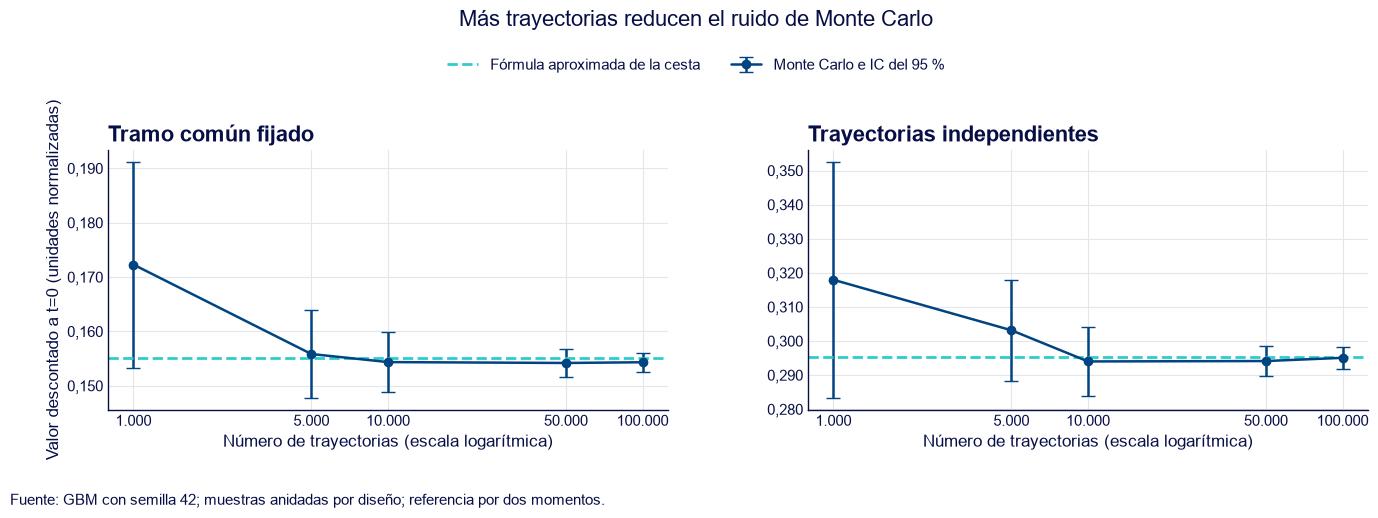

Guardado: Graficos\mc_convergencia_coste.png


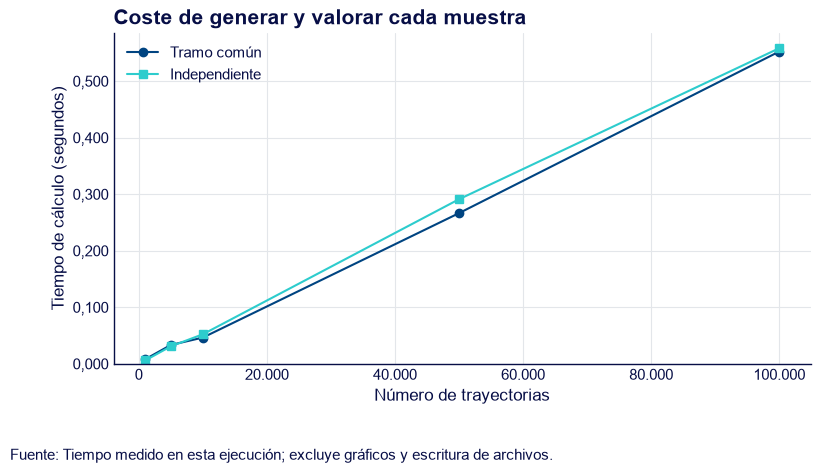

In [20]:
fig_convergencia, axes_convergencia = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

def dibujar_convergencia(ax, estudio, aproximacion, titulo):
    """Representa estimaciones e intervalos MC junto a la fórmula aproximada."""
    ax.errorbar(estudio[:, 0], estudio[:, 1], yerr=1.96 * estudio[:, 2],
                fmt="o-", color=BBVA["principal"], capsize=5, linewidth=1.8,
                label="Monte Carlo e IC del 95 %")
    ax.axhline(aproximacion, color=BBVA["agua"], linestyle="--", linewidth=2,
               label="Fórmula aproximada de la cesta")
    ax.set(title=titulo, xlabel="Número de trayectorias (escala logarítmica)", xscale="log")
    ax.set_xticks(estudio[:, 0])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor)))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor, 3)))

dibujar_convergencia(axes_convergencia[0], estudio_condicionado,
                     prima_aprox_condicionada, "Tramo común fijado")
dibujar_convergencia(axes_convergencia[1], estudio_independiente,
                     prima_aprox_independiente, "Trayectorias independientes")
axes_convergencia[0].set_ylabel("Valor descontado a t=0 (unidades normalizadas)")
fig_convergencia.legend(*axes_convergencia[0].get_legend_handles_labels(),
    loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=2)
fig_convergencia.suptitle("Más trayectorias reducen el ruido de Monte Carlo", fontsize=16)
fig_convergencia.subplots_adjust(left=0.08, right=0.98, bottom=0.18, top=0.7, wspace=0.25)
cerrar_grafico(fig_convergencia, "mc_convergencia_primas", fuente="GBM con semilla 42; muestras anidadas por diseño; referencia por dos momentos.", ajustar_titulos=False)

fig_coste, ax_coste = plt.subplots(figsize=(9, 4.8))
ax_coste.plot(estudio_condicionado[:, 0], estudio_condicionado[:, 3], "o-",
              color=BBVA["principal"], label="Tramo común")
ax_coste.plot(estudio_independiente[:, 0], estudio_independiente[:, 3], "s-",
              color=BBVA["agua"], label="Independiente")
ax_coste.set(xlabel="Número de trayectorias", ylabel="Tiempo de cálculo (segundos)")
ax_coste.set_title("Coste de generar y valorar cada muestra", fontsize=15)
ax_coste.set_ylim(bottom=0)
ax_coste.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor)))
ax_coste.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: fmt_es(valor, 3)))
ax_coste.legend()
fig_coste.subplots_adjust(bottom=0.19)
cerrar_grafico(fig_coste, "mc_convergencia_coste", fuente="Tiempo medido en esta ejecución; excluye gráficos y escritura de archivos.", ajustar_titulos=False)


## 13. Organización de los resultados

Los precios, los retornos, los payoffs y los valores descontados se reúnen en **resultados_montecarlo**, junto con los parámetros utilizados. Se conserva la correspondencia entre cada trayectoria y sus resultados mediante **id_simulacion**.

Los retornos de cada paso se obtienen a partir de los precios simulados:

$$
R^{\log}_{h,j,k}=\ln\frac{S^k_{h,j}}{S^k_{h,j-1}},
\qquad
R^{\mathrm{simple}}_{h,j,k}=e^{R^{\log}_{h,j,k}}-1.
$$

En el primer paso se utiliza $S_0$ como precio anterior. Los retornos son **trimestrales**, sin anualizar, y conservan la forma **(100000, 20, 3)** y el orden **CAT, MRK, MSFT**.

También se conservan **n_pasos_comunes**, **t_bifurcacion** y **trayectoria_comun** para identificar la historia compartida y distinguirla de las continuaciones.

La primera fila de cada array corresponde a la simulación 1. El primer paso representa $t=0,25$ y el último, $t=5$. Los arrays conservan los valores completos; el redondeo se aplica únicamente a las tablas mostradas.


In [21]:
retornos_log_simulados = np.diff(np.log(X / S0), axis=1, prepend=0.0)
retornos_simples_simulados = np.expm1(retornos_log_simulados)

resultados_montecarlo = {
    "X": X,
    "retornos_log": retornos_log_simulados,
    "retornos_simples": retornos_simples_simulados,
    "payoff": payoff,
    "Y": Y,
    "id_simulacion": simulaciones.to_numpy(),
    "tiempos": tiempos,
    "activos": np.asarray(activos),
    "S0": S0,
    "sigma": sigma,
    "rho": rho,
    "r": r,
    "TTM": TTM,
    "dt": dt,
    "strike": strike,
    "semilla": semilla,
    "num_sims": num_sims,
    "num_pasos": num_pasos,
    "n_pasos_comunes": n_pasos_comunes,
    "t_bifurcacion": t_bifurcacion,
    "trayectoria_comun": X[0, :n_pasos_comunes, :].copy(),
    "periodo_estimacion": np.array(["2016-01-05", "2025-12-31"]),
}

df_resultados = pd.DataFrame({
    "Variable": ["X", "retornos_log", "retornos_simples", "payoff", "Y", "id_simulacion", "tiempos"],
    "Forma": [
        str(X.shape), str(retornos_log_simulados.shape),
        str(retornos_simples_simulados.shape), str(payoff.shape),
        str(Y.shape), str(simulaciones.shape), str(tiempos.shape),
    ],
    "Contenido": [
        "Precios normalizados", "Retornos logarítmicos trimestrales",
        "Retornos simples trimestrales", "Payoff final por trayectoria",
        "Payoff descontado por trayectoria e instante",
        "Identificadores de las trayectorias", "Instantes en años",
    ],
})
display(Markdown("**Estructura de los resultados de Monte Carlo**"), df_resultados)


**Estructura de los resultados de Monte Carlo**

,Variable,Forma,Contenido
0,X,"(100000, 20, 3)",Precios normalizados
1,retornos_log,"(100000, 20, 3)",Retornos logarítmicos trimestrales
2,retornos_simples,"(100000, 20, 3)",Retornos simples trimestrales
3,payoff,"(100000,)",Payoff final por trayectoria
4,Y,"(100000, 20)",Payoff descontado por trayectoria e instante
5,id_simulacion,"(100000,)",Identificadores de las trayectorias
6,tiempos,"(20,)",Instantes en años


### Guardado de gráficos y exportación opcional

Los ocho gráficos se guardan automáticamente como PNG en `Graficos/`: abanico general, primeras cinco trayectorias, muestra de 100 trayectorias, precios finales, retornos de las continuaciones, payoffs positivos, convergencia de las estimaciones y coste por tamaño.

La exportación de arrays se activa con **exportar_resultados = True** y guarda `resultados_montecarlo.npz` en la carpeta de ejecución. Conserva los resultados de la simulación principal y sus parámetros completos, sin redondearlos. Esta exportación permanece desactivada por defecto y no es necesaria para ejecutar el notebook.

El archivo exportado puede abrirse con `np.load("resultados_montecarlo.npz", allow_pickle=False)`. La referencia independiente y los contrastes analíticos se mantienen separados del diccionario principal.


In [22]:
exportar_resultados = False

if exportar_resultados:
    ruta_resultados = Path("resultados_montecarlo.npz")
    np.savez_compressed(ruta_resultados, **resultados_montecarlo)
    print(f"Guardado: {ruta_resultados.resolve()}")


## Resultados disponibles

- **X:** precios normalizados de las 100.000 trayectorias en los 20 instantes.
- **df_precios_anuales:** primeras cinco trayectorias en los cinco cierres anuales.
- **payoff** y **df_payoffs:** pagos finales y medias geométricas de cada simulación.
- **Y** y **df_primas:** payoffs descontados en los 20 instantes trimestrales.
- **df_primas_anuales:** ejemplos anuales y media de la muestra.
- **df_primas_trimestrales:** media y error estándar en las 20 fechas.
- **df_martingala:** contraste de los precios terminales descontados de la muestra independiente.
- **df_resumen:** valoración condicionada al tramo inicial y medidas de precisión de Monte Carlo.
- **df_validacion**, **df_correlacion_simulada** y **df_media_terminal:** comprobaciones de la simulación principal.
- **df_comparacion:** comparación entre valoración condicionada e incondicional.
- **df_validacion_asiatica:** contraste exacto auxiliar de CAT.
- **df_cesta_aproximada:** comparación de Monte Carlo con la aproximación de dos momentos para la cesta.
- **df_convergencia** y **df_precision_objetivo:** estimaciones, errores y tiempos para cinco tamaños de muestra.
- **resultados_montecarlo:** conjunto de resultados y parámetros disponible para la exportación opcional.

Los parámetros se estiman con el histórico 2016–2025 y las trayectorias representan un horizonte futuro de cinco años. Los precios y los pagos están normalizados. El error estándar cuantifica el ruido del estimador de Monte Carlo de las continuaciones bajo los parámetros y la historia inicial fijados.


In [23]:
assert len(df_primas_trimestrales) == num_pasos
assert np.allclose(df_primas_trimestrales["Media del payoff descontado"], Y.mean(axis=0))
assert np.allclose(np.cumsum(retornos_log_simulados, axis=1), np.log(X / S0))
assert np.allclose(resultados_montecarlo["trayectoria_comun"], X[0, :n_pasos_comunes])
assert np.isclose(prima_bifurcacion, prima_t0 * np.exp(r * t_bifurcacion))
assert np.isclose(prima_aprox_bifurcacion, prima_aprox_condicionada * np.exp(r * t_bifurcacion))
print("Revisión final correcta: tablas, retornos, correspondencia de arrays y descuentos.")


Revisión final correcta: tablas, retornos, correspondencia de arrays y descuentos.


## Conclusiones de los resultados

Con **100.000 continuaciones, 20 pasos trimestrales y semilla 42**, las trayectorias comparten los cinco primeros pasos hasta **1,25 años** y después se separan. El abanico muestra que la dispersión aumenta durante los 15 pasos restantes; las bandas resumen esa dispersión sin ocultar el tramo común.

El payoff medio al vencimiento es **0,162241** y la prima condicionada al final del tramo común es **0,156269**. La media descontada a $t=0$ es **0,154328**. Son valores en unidades normalizadas, no directamente en euros, y corresponden a la historia inicial fijada, no a una valoración inicial que promedie todas las historias posibles.

El **61,09 %** de las continuaciones termina con un payoff de cero y el **38,91 %** genera un pago positivo. Los precios compartidos al inicio no garantizan un pago común al final: las continuaciones posteriores determinan medias geométricas y payoffs distintos.

La media de los payoffs descontados pasa de **0,154328** en el origen a **0,162241** en el año 5. Esta diferencia se debe al menor tiempo de descuento del mismo pago final y no a un crecimiento garantizado del valor de la opción.

El error estándar de la media descontada a $t=0$ es **0,000905**. Mide la variabilidad de Monte Carlo de las continuaciones condicionadas al tramo común; no recoge la incertidumbre de los parámetros ni la variabilidad de historias iniciales alternativas.

La referencia con 20 pasos independientes estima una prima inicial incondicional de **0,295072**, con error estándar **0,001624** y **44,129 %** de pagos positivos. No contradice el resultado principal: promedia historias iniciales distintas, mientras que la simulación principal fija una sola. Cambiar el tramo común puede modificar considerablemente la valoración; aumentar las continuaciones solo reduce el ruido alrededor del valor condicionado a ese tramo.

Las verificaciones reproducen las correlaciones y los precios terminales esperados **condicionados** al tramo inicial. La prueba auxiliar sobre CAT obtiene **0,146487** por Monte Carlo frente a **0,146999** con la fórmula geométrica discreta, una diferencia de **0,58 errores estándar**. Esta comprobación valida el esquema de simulación y de promedio temporal para un solo activo; no es una fórmula exacta para la cesta.

La fórmula aproximada de dos momentos para la cesta obtiene **0,155096** descontado al origen con el tramo común fijado, frente a **0,154328** de Monte Carlo, una diferencia relativa del **0,50 %**. Para la referencia independiente obtiene **0,295252**, frente a **0,295072**, una diferencia del **0,06 %**. En esta ejecución ambas aproximaciones quedan dentro de los intervalos Monte Carlo del 95 %. Esta concordancia no convierte la fórmula de la cesta en exacta: el ajuste lognormal puede introducir sesgo.

El estudio de convergencia utiliza cinco tamaños entre **1.000 y 100.000** trayectorias. El primer tamaño probado que cumple una semiamplitud relativa del intervalo del 95 % de como máximo el **2 %** es **50.000**, en ambos diseños. Se mantienen **100.000** para disponer de mayor precisión: la semiamplitud relativa es **1,15 %** con el tramo común y **1,08 %** con trayectorias independientes. La estimación no evoluciona de forma estrictamente monótona, mientras que el error estándar disminuye en los tamaños ensayados. El coste medido aumenta con el tamaño de la muestra y depende del equipo y de la carga durante la ejecución.

La validación de la referencia independiente obtiene errores relativos inferiores al **0,31 %** en los precios terminales descontados respecto a los precios iniciales, por debajo de la tolerancia del 1 %. Las tablas trimestrales, los histogramas y los ocho gráficos conservan la correspondencia con las mismas matrices de simulación.
